# Label-frequency correction, graph SVMs and Other subgroups

The requested follow-up tested **84 configurations**: 24 label-shift corrections, 36 graph-regularized SVMs and 24 Other-subclass models. The starting candidate had validation sample-wise F1 **0.912393**. The current saved candidate has **0.912393**. Validation remains excluded from fitting; the final train-plus-validation refit is deferred.

The reported Kaggle leader is in the 0.93xx range; its exact score is unknown. Our actual Kaggle score is unmeasured. Local CV and validation are separate evaluations.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd
import matplotlib.pyplot as plt
root=Path.cwd()
summary=json.loads((root/'experiments/phase26-summary.json').read_text())
summary

{'raw_configurations': 84,
 'family_counts': {'label_shift26': 24,
  'lap_svm26': 36,
  'other_subclasses26': 24},
 'baseline_validation_f1': 0.9123931623931625,
 'baseline_matched_cv': 0.9174805378627034,
 'repeat_seeds': [20261123, 20261124, 20261125],
 'validation_comparisons': 6,
 'results': [{'name': 'phase26_label_shift26',
   'matched_control': False,
   'cv': 0.9306440198159943,
   'cv_std': 0.003608647921863222,
   'validation': 0.8717948717948718,
   'macro': 0.7537373737373738},
  {'name': 'phase26_lap_svm26',
   'matched_control': False,
   'cv': 0.9221514508138712,
   'cv_std': 0.003608647921863222,
   'validation': 0.8803418803418804,
   'macro': 0.7651592851592852},
  {'name': 'phase26_other_subclasses26',
   'matched_control': False,
   'cv': 0.9281670205237084,
   'cv_std': 0.00563955323797212,
   'validation': 0.8974358974358975,
   'macro': 0.7713131313131314},
  {'name': 'phase26_control_label_shift26',
   'matched_control': True,
   'cv': 0.9313517338995045,
   'cv

## Label-frequency correction

The teacher combines the incumbent's SVM scores for Safety/Funding/Efficacy and tri-training scores for Recruitment/Other. SVM scores are aligned so their previous 0.55 threshold corresponds to 0.5. A five-fold grouped inner CV supplies teacher scores for every outer-training gold row. Logistic calibrators (C=0.3 or 3) fit those OOF scores to the original binary labels.

The full-fold teacher predicts the allowed masked training examples. Two estimators infer each reason's prevalence in those examples: regularized soft-confusion inversion (a binary BBSE adaptation) and an EM likelihood update with 20 source-prior pseudo-observations. BBSE uses ridge 0.01 toward the labeled source frequency. Estimated prevalences are clipped to [0.01,0.99]. The log-odds adjustment is capped at ±1.5 and multiplied by 0.25, 0.5 or 1.

The shift is applied either to calibrated scores or the original aligned teacher scores. The uncalibrated-score variant is a heuristic comparison. Calibration summaries and prevalence estimates are training estimates, not independent accuracy guarantees. The method assumes stable score distributions conditional on each reason; deliberate rare-label sampling, changing trial years and correlated labels can violate this assumption.

Only the 1,014 originally masked training rows, with held-out embedding duplicates removed, inform target prevalence. Validation and test features do not enter prior estimation. The matched control sets the shift strength to zero and keeps the same calibration, threshold and scope.

## Graph-regularized SVM

Each training fold fits StandardScaler and a 192-component Nystroem approximation of the RBF kernel. A graph joins the 10 or 25 nearest neighbors among allowed gold and masked training embeddings. Edge weights use local distance scales; the graph is symmetrized. Its combinatorial Laplacian is $L=D-W$.

Writing the finite feature matrix as $\Phi$, compute $G=\Phi^T L\Phi/N$ and scale it to mean diagonal one. For each reason, minimize

$$\tfrac12 w^T(I+\lambda G)w+C\sum_{i\in\mathrm{gold}} a_i\max(0,1-y_i(\phi_i^Tw+b)).$$

Cholesky whitening converts this objective to an ordinary balanced SVM. The graph weights tested are 0.1, 1 and 10; C is 0.3, 1 or 3; RBF gamma is 0.001 or 0.003. Only gold labels enter the hinge loss. The unsupervised graph changes the fitted classifier, whose predictions supply the missing labels. This is a finite-kernel approximation of a Laplacian SVM, not an exact infinite-dimensional solver.

The matched control uses the identical kernel approximation and settings with graph weight zero. Its purpose is to isolate the graph penalty. Query features only undergo the fitted transformations; they never alter the graph.

## Other subgroups

PCA to 25 components is fitted on permitted training embeddings. KMeans then clusters the gold Other-positive rows into two or three subgroups. If a subgroup contains fewer than three gold examples, the number of subgroups is reduced. All Other-negative gold examples remain class zero.

A regularized multiclass logistic classifier learns these latent subclass targets. Its Other score is the sum of probabilities for the positive subclasses. The representation is either standardized embeddings or a 192-component RBF kernel map. C is 0.3, 1 or 3. Aggregate Other versus non-Other receives balanced gold weights; each positive subclass is not independently rebalanced to the size of the negative class.

Masked rows whose teacher Other score is at least 0.8 or at most 0.2 receive fixed provisional targets with weight 0.03. Positive provisional rows are assigned to the nearest learned Other center. The resulting score replaces or blends equally with the incumbent's Other score. Other reason decisions are preserved by the scoped policy. Original gold labels are never overwritten.

The matched control uses one Other subgroup with identical remaining settings. This isolates the benefit of splitting the positive class.

## Selection and validation discipline

The first screen uses grouped five-fold CV seed 20261122. Four thresholds (0.4/0.5/0.6/0.7) and four label scopes are considered for shift and graph models; subclass models alter only Other. Scope choices for the first two families are all labels, Safety/Funding/Efficacy, Efficacy/Other, or Recruitment/Other. Empty scoped predictions fall back to the incumbent's decisions.

Ordinary and robust weighted CV each nominate a policy per family. Up to six policies are frozen and evaluated on three new grouped split seeds (20261123–20261125). Selection within each family maximizes mean sample-F1 minus 0.2 times its split standard deviation, with robust weighted performance breaking ties. Matched controls inherit the chosen settings, scope and threshold without retuning.

The three finalists and three controls are frozen before validation evaluation. Their validation predictions are saved before validation labels are read for reporting. The original engine also logs its best decoding rule for diagnostic purposes; phase 26 selection uses only the explicit frozen policies described here.

The repeated full history of CV and validation comparisons creates selection optimism. A nested inner calibrator does not make the entire historical search an unbiased nested-CV estimate. All duplicate reason embeddings are grouped, and matching masked duplicates of held-out groups are excluded at every fitting level.

In [2]:
repeats=json.loads((root/'experiments/phase26-repeat-results.json').read_text())
pd.DataFrame([dict(family=r['config']['learner']['model'],scope=r['config']['scope'],threshold=r['config']['decision_rule'],mean_cv=r['ordinary_cv'],split_std=r['cv_std'],settings=json.dumps(r['config']['learner'],sort_keys=True)) for r in repeats])

,family,scope,threshold,mean_cv,split_std,settings
0,label_shift26,efficacy_other,t0.6,0.930644,0.003609,"{""calibration_C"": 0.3, ""method"": ""em"", ""model""..."
1,label_shift26,rare,t0.5,0.920311,0.003740,"{""calibration_C"": 3, ""method"": ""em"", ""model"": ..."
2,lap_svm26,efficacy_other,t0.7,0.922151,0.004003,"{""C"": 3, ""gamma"": 0.001, ""graph_weight"": 1, ""m..."
3,lap_svm26,efficacy_other,t0.7,0.922151,0.003609,"{""C"": 3, ""gamma"": 0.003, ""graph_weight"": 0.1, ..."
4,other_subclasses26,other,t0.7,0.923921,0.008419,"{""C"": 1, ""mix"": 1, ""model"": ""other_subclasses2..."
5,other_subclasses26,other,t0.7,0.928167,0.005640,"{""C"": 3, ""mix"": 1, ""model"": ""other_subclasses2..."


In [3]:
results=json.loads((root/'experiments/phase26-validation-results.json').read_text())
table=pd.DataFrame([dict(candidate=r['name'],control=r['matched_control'],cv=r['ordinary_cv'],validation_f1=r['validation']['sample_f1'],macro_f1=r['validation']['macro_f1']) for r in results])
table

,candidate,control,cv,validation_f1,macro_f1
0,phase26_label_shift26,False,0.930644,0.871795,0.753737
1,phase26_lap_svm26,False,0.922151,0.880342,0.765159
2,phase26_other_subclasses26,False,0.928167,0.897436,0.771313
3,phase26_control_label_shift26,True,0.931352,0.876068,0.758932
4,phase26_control_lap_svm26,True,0.922151,0.858974,0.744202
5,phase26_control_other_subclasses26,True,0.927105,0.897436,0.771313


## What the controls establish

None of the three finalists or controls exceeds the retained 0.912393 validation model. Label-frequency correction scores 0.871795 versus 0.876068 without the shift, so correction itself does not explain a gain. The graph penalty scores 0.880342 versus 0.858974 without that penalty, an improvement within this matched pair that still trails the incumbent. Three Other subgroups score 0.897436, exactly the same aggregate validation F1 as one subgroup.

The selected frequency-correction policy reaches 0.930644 on repeated training CV but loses substantially on validation. Its zero-shift control also has high CV and lower validation. This supports caution about transferring training-CV rankings; it does not by itself prove a particular cause of the mismatch or a Kaggle score. The incumbent is preserved rather than replacing it based on CV alone.

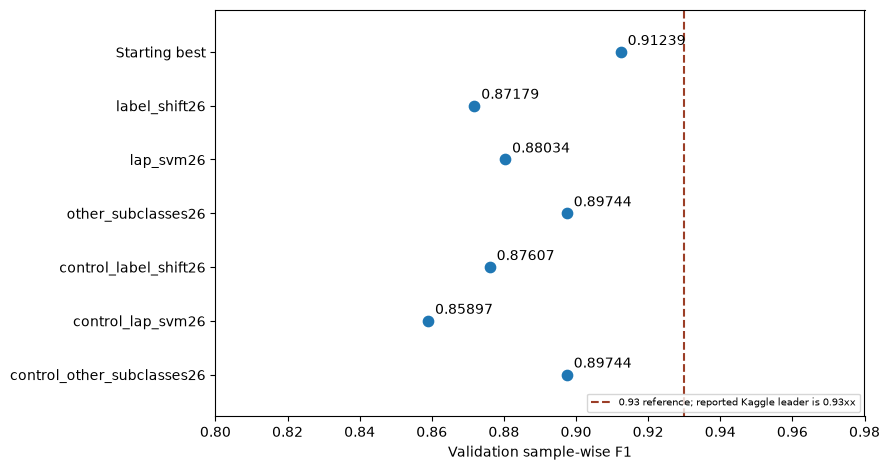

In [4]:
names=['Starting best']+table.candidate.str.replace('phase26_','',regex=False).tolist()
scores=[summary['baseline_validation_f1']]+table.validation_f1.tolist()
fig,ax=plt.subplots(figsize=(9,4.8))
y=np.arange(len(names));ax.scatter(scores,y,s=55)
for i,s in enumerate(scores):ax.annotate(f'{s:.5f}',(s,i),xytext=(5,5),textcoords='offset points')
ax.axvline(.93,color='#9b3e27',linestyle='--',label='0.93 reference; reported Kaggle leader is 0.93xx')
ax.set(yticks=y,yticklabels=names,xlim=(min(.80,min(scores)-.02),max(.98,max(scores)+.02)),xlabel='Validation sample-wise F1')
ax.margins(y=.13);ax.invert_yaxis();ax.legend(loc='lower right',fontsize=7)
fig.tight_layout();fig.savefig(root/'figures/current_phase26_comparison.png',dpi=180)
plt.show()

## Integrity and reproduction

All three methods pass held-out-label perturbation, query-label invariance, query-batch invariance, masked-duplicate exclusion and consistent query/masked output tests. Additional checks confirm the graph objective's algebraic transformation, equality with an ordinary finite-kernel SVM when the graph penalty is zero, and zero-shift equality with the aligned teacher scores. Synthetic label-shift inputs verify adjustment direction.

No external trial data, added labels, ID predictors or deep learning are used. Source is embedded in notebook 04. Exact configurations, OOF outputs, selection records and diagnostics are stored under `experiments/phase26*`. Raw input hashes and preservation of all 157 original gold labels are checked when reproducing the retained candidate.

References: [label-shift estimation](https://proceedings.mlr.press/v80/lipton18a.html) and [manifold regularization](https://www.jmlr.org/papers/v7/belkin06a.html).

In [5]:
json.loads((root/'experiments/phase26-integrity-checks.json').read_text())

{'passed': True,
 'checks': [{'model': 'label_shift26',
   'heldout_label_invariance': True,
   'query_batch_invariance': True,
   'masked_duplicate_exclusion': True,
   'query_label_invariance': True,
   'unlabeled_output_consistency': True},
  {'model': 'lap_svm26',
   'heldout_label_invariance': True,
   'query_batch_invariance': True,
   'masked_duplicate_exclusion': True,
   'query_label_invariance': True,
   'unlabeled_output_consistency': True},
  {'model': 'other_subclasses26',
   'heldout_label_invariance': True,
   'query_batch_invariance': True,
   'masked_duplicate_exclusion': True,
   'query_label_invariance': True,
   'unlabeled_output_consistency': True}],
 'graph_objective_equivalence': True,
 'zero_graph_matches_finite_kernel_svm': True,
 'zero_shift_matches_raw_scores': True,
 'synthetic_prior_shift_direction': True,
 'caches_cleared': True,
 'validation_fit': False,
 'source_sha256': {'phase26.py': '82f76d2f4e6278d63bd13924d1147fa25c723881f794afd932165e2bf4050bc8',
 